In [ ]:
# Regresie Multivariata -> Metoda celor mai mici patrate

In [2]:
import csv
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn import linear_model


In [3]:
def loadData(fileName, firstInputVariabName, secondInputvariabName,outputVariabName):
    data = []
    dataNames = []
    with open(fileName) as csv_file:
        csv_reader = csv.reader(csv_file, delimiter=',')
        line_count = 0
        for row in csv_reader:
            if line_count == 0:
                dataNames = row
            else:
                data.append(row)
            line_count += 1

    firstSelectedVariable = dataNames.index(firstInputVariabName)
    secondSelectedVariable = dataNames.index(secondInputvariabName)
    selectedOutput = dataNames.index(outputVariabName)

    firstInputs = []
    secondInputs = []
    outputs = []

    for i in range(len(data)):
        if (
            data[i][firstSelectedVariable] != '' and
            data[i][secondSelectedVariable] != '' and
            data[i][selectedOutput] != ''
        ):
            firstInputs.append(float(data[i][firstSelectedVariable]))
            secondInputs.append(float(data[i][secondSelectedVariable]))
            outputs.append(float(data[i][selectedOutput]))

    return firstInputs, secondInputs, outputs

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v1_world-happiness-report-2017.csv')

firstInputs, secondInputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Freedom', 'Happiness.Score')
print('in:  ', firstInputs[:5])
print('in:  ', secondInputs[:5])
print('out: ', outputs[:5])


in:   [1.616463184, 1.482383013, 1.48063302, 1.564979553, 1.443571925]
in:   [0.635422587, 0.626006722, 0.627162635, 0.620070577, 0.617950857]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


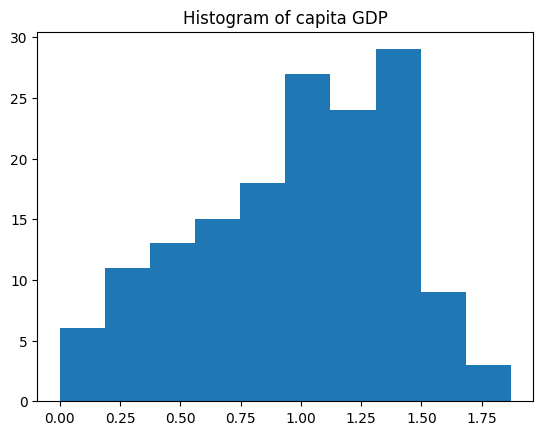

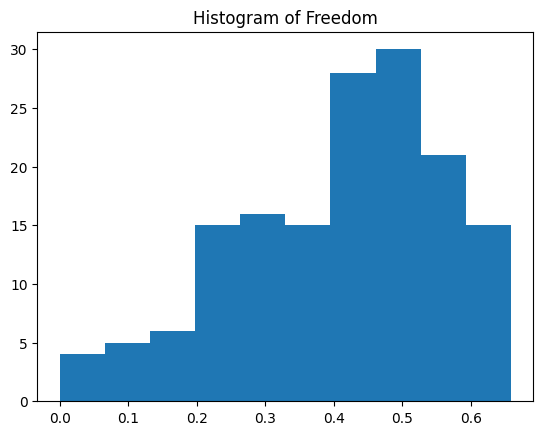

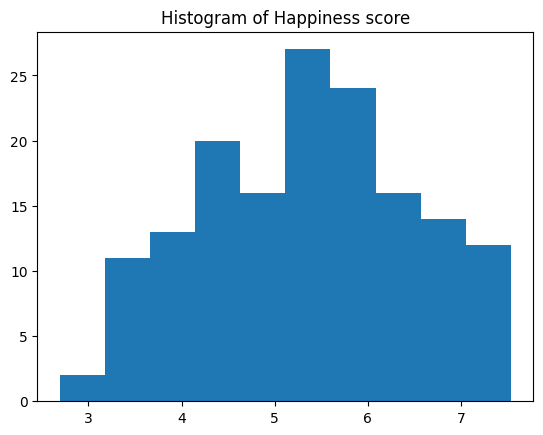

In [4]:
def plotDataHistogram(x, variableName):
    plt.hist(x, 10)
    plt.title('Histogram of ' + variableName)
    plt.show()

plotDataHistogram(firstInputs, 'capita GDP')
plotDataHistogram(secondInputs, 'Freedom')
plotDataHistogram(outputs, 'Happiness score')



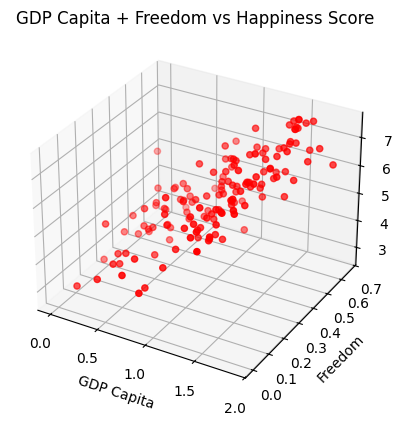

In [5]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

def checkLinearity3D(firstInputs, secondInputs, outputs):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(firstInputs, secondInputs, outputs, c='red', marker='o')

    ax.set_xlabel('GDP Capita')
    ax.set_ylabel('Freedom')
    ax.set_zlabel('Happiness Score')
    ax.set_title('GDP Capita + Freedom vs Happiness Score')

    plt.show()


checkLinearity3D(firstInputs, secondInputs, outputs)

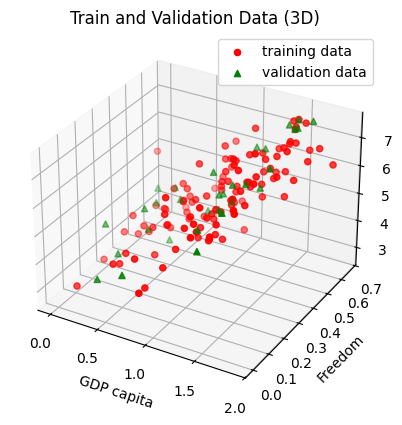

In [6]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

def splitTrainingTest2D(inputs_param, outputs_param):
    np.random.seed(5)
    indexes = [i for i in range(len(inputs_param))]
    trainSample = np.random.choice(indexes, int(0.8 * len(inputs_param)), replace=False)
    validationSample = [i for i in indexes if i not in trainSample]

    trainInputs = [inputs_param[i] for i in trainSample]
    trainOutputs = [outputs_param[i] for i in trainSample]

    validationInputs = [inputs_param[i] for i in validationSample]
    validationOutputs = [outputs_param[i] for i in validationSample]

    return trainInputs, trainOutputs, validationInputs, validationOutputs


def plotTrainParams3D(trainInputs, trainOutputs, validationInputs, validationOutputs):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    # separăm componentele inputurilor (x1, x2)
    trainX1 = [x[0] for x in trainInputs]
    trainX2 = [x[1] for x in trainInputs]

    valX1 = [x[0] for x in validationInputs]
    valX2 = [x[1] for x in validationInputs]

    ax.scatter(trainX1, trainX2, trainOutputs, c='red', marker='o', label='training data')
    ax.scatter(valX1, valX2, validationOutputs, c='green', marker='^', label='validation data')

    ax.set_xlabel('GDP capita')
    ax.set_ylabel('Freedom')
    ax.set_zlabel('Happiness score')
    ax.set_title('Train and Validation Data (3D)')
    ax.legend()
    plt.show()

inputs = list(zip(firstInputs, secondInputs))
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
plotTrainParams3D(trainInputs, trainOutputs, validationInputs, validationOutputs)


In [7]:
from sklearn import linear_model

def trainWithTool2D(trainInputs_param, trainOutputs_param):
    xx = [list(el) for el in trainInputs_param]

    regressor = linear_model.LinearRegression()

    regressor.fit(xx, trainOutputs_param)

    w0 = regressor.intercept_
    w = regressor.coef_

    return regressor, w0, w

def printToolRegression2D(w0, w):
    print(f'The learnt model: f(x1, x2) = {w0:.4f} + ({w[0]:.4f}) * x1 + ({w[1]:.4f}) * x2')


inputs = list(zip(firstInputs, secondInputs))
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
regressor, w0, w = trainWithTool2D(trainInputs, trainOutputs)

printToolRegression2D(w0, w)


The learnt model: f(x1, x2) = 2.5284 + (1.8763) * x1 + (2.3147) * x2


In [13]:
from MyLinearMultivariateRegression import MyLinearMultivariateRegression

def trainWithDevelopedCode2D(trainInputs_param, trainOutputs_param):
    regressor = MyLinearMultivariateRegression()
    regressor.fit(trainInputs_param, trainOutputs_param)
    w0 = regressor.weights[0]
    w = regressor.weights[1:]
    return regressor, w0, w


def printDevelopedRegression2D(w0, w):
    print(f"The learnt model: f(x1, x2) = {w0:.4f} + ({w[0]:.4f}) * x1 + ({w[1]:.4f}) * x2")

inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
regressor, w0, w = trainWithDevelopedCode2D(trainInputs, trainOutputs)

printDevelopedRegression2D(w0, w)


The learnt model: f(x1, x2) = 2.5284 + (1.8763) * x1 + (2.3147) * x2


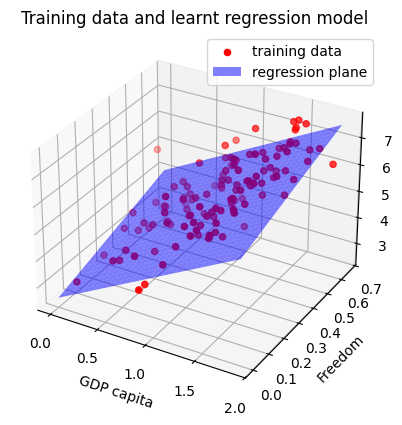

In [15]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

def plotLearntModel2D(trainInputs_param, trainOutputs_param):
    # Antrenăm modelul cu două features
    regressor, w0, w = trainWithTool2D(trainInputs_param, trainOutputs_param)  # w este [w1, w2]

    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    # Datele reale (punctele de antrenament)
    x1 = [x[0] for x in trainInputs_param]
    x2 = [x[1] for x in trainInputs_param]
    y = trainOutputs_param
    ax.scatter(x1, x2, y, c='red', marker='o', label='training data')

    # Generăm planul în 3D
    x1_range = np.linspace(min(x1), max(x1), 30)
    x2_range = np.linspace(min(x2), max(x2), 30)
    x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)
    y_grid = w0 + w[0] * x1_grid + w[1] * x2_grid

    ax.plot_surface(x1_grid, x2_grid, y_grid, alpha=0.5, color='blue', label='regression plane')

    ax.set_xlabel('GDP capita')
    ax.set_ylabel('Freedom')
    ax.set_zlabel('Happiness')
    ax.set_title('Training data and learnt regression model')
    plt.legend()
    plt.show()


inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)

plotLearntModel2D(trainInputs, trainOutputs)



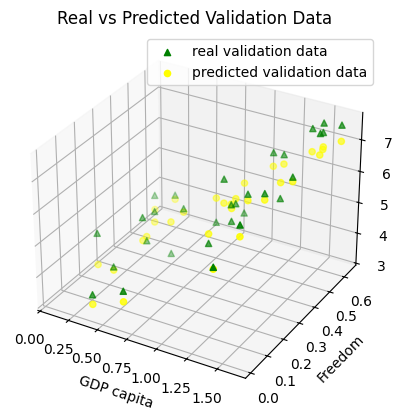

In [16]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

def predictData2D(trainInputs_param, trainOutputs_param, validationInputs_param):
    regressor, w0, w = trainWithTool2D(trainInputs_param, trainOutputs_param)
    computedValidationOutputs = regressor.predict(validationInputs_param)
    return computedValidationOutputs



def plotComputedValidationOutputs3D(validationInputs_param, validationOutputs_param, computedValidationOutputs_param):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    x1 = [x[0] for x in validationInputs_param]
    x2 = [x[1] for x in validationInputs_param]

    # Puncte reale
    ax.scatter(x1, x2, validationOutputs_param, c='green', marker='^', label='real validation data')

    # Puncte estimate
    ax.scatter(x1, x2, computedValidationOutputs_param, c='yellow', marker='o', label='predicted validation data')

    ax.set_xlabel('GDP capita')
    ax.set_ylabel('Freedom')
    ax.set_zlabel('Happiness')
    ax.set_title('Real vs Predicted Validation Data')
    ax.legend()
    plt.show()


inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)

computedValidationOutputs = predictData2D(trainInputs, trainOutputs, validationInputs)
plotComputedValidationOutputs3D(validationInputs, validationOutputs, computedValidationOutputs)


In [17]:
def getError(computedValidationOutputs_param, validationOutputs_param):
    error = 0.0
    for t1, t2 in zip(computedValidationOutputs_param, validationOutputs_param):
        error += (t1 - t2) ** 2
    error = error / len(validationOutputs_param)
    print('prediction error (manual): ', error)

    # by using sklearn
    from sklearn.metrics import mean_squared_error

    error = mean_squared_error(validationOutputs_param, computedValidationOutputs_param)
    print('prediction error (tool):  ', error)


trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
computedValidationOutputs = predictData2D(trainInputs, trainOutputs, validationInputs)
getError(computedValidationOutputs, validationOutputs)


prediction error (manual):  0.2778267436200108
prediction error (tool):   0.2778267436200108


Pas 1

in:   [1.616463184, 1.482383013, 1.48063302, 1.564979553, 1.443571925]
in:   [0.808231592, 0.741191506, 0.74031651, 0.782489777, 0.721785963]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


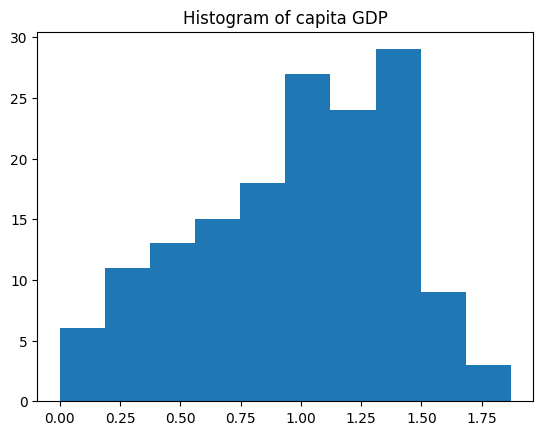

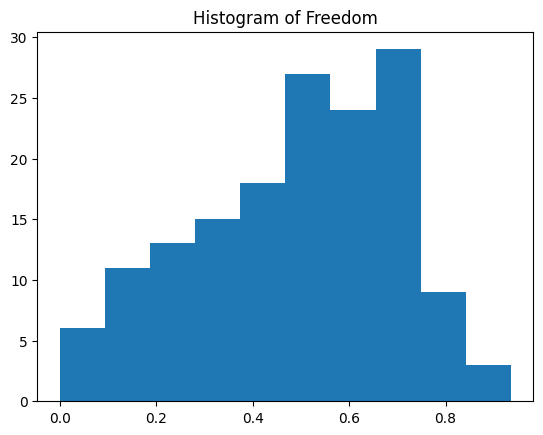

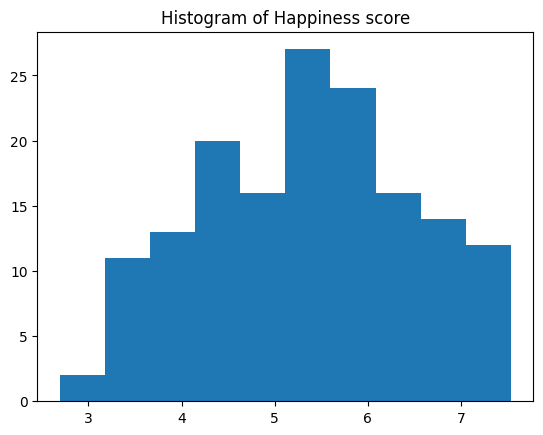

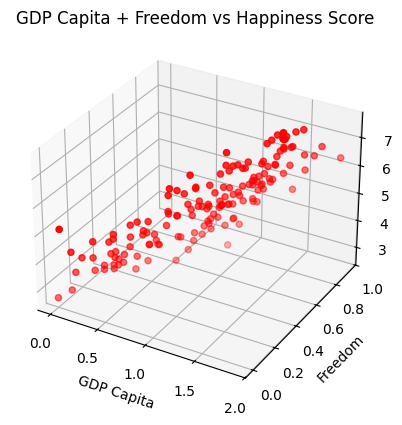


Pas 2



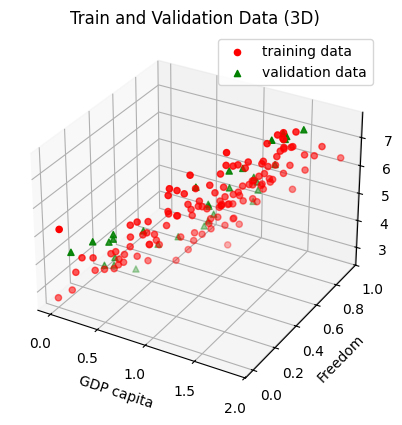


Pas 3

The learnt model: f(x1, x2) = 3.2008 + (-68616.1990) * x1 + (137236.6987) * x2
The learnt model: f(x) = 3.2008 + (309.8624) * x

Pas 4



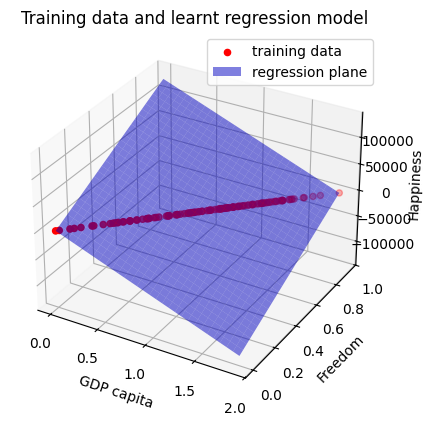

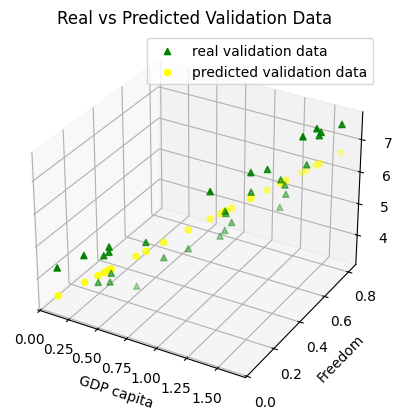


Pas 5

prediction error (manual):  0.4142102429499824
prediction error (tool):   0.4142102429499823


In [22]:
# DATE V2 -> GDP + Freedom


print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v2_world-happiness-report-2017.csv')

firstInputs, secondInputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Freedom', 'Happiness.Score')
print('in:  ', firstInputs[:5])
print('in:  ', secondInputs[:5])
print('out: ', outputs[:5])




plotDataHistogram(firstInputs, 'capita GDP')
plotDataHistogram(secondInputs, 'Freedom')
plotDataHistogram(outputs, 'Happiness score')



checkLinearity3D(firstInputs, secondInputs, outputs)

print()
print("Pas 2")
print()


inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
plotTrainParams3D(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()


inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
regressor, w0, w = trainWithTool2D(trainInputs, trainOutputs)

printToolRegression2D(w0, w)

inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)


inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)

regressor, w0, w = trainWithDevelopedCode2D(trainInputs, trainOutputs)

print(f"The learnt model: f(x) = {w0:.4f} + ({w[0]:.4f}) * x")


print()
print("Pas 4")
print()



inputs = list(zip(firstInputs, secondInputs))
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
plotLearntModel2D(trainInputs, trainOutputs)
computedValidationOutputs = predictData2D(trainInputs, trainOutputs, validationInputs)
plotComputedValidationOutputs3D(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData2D(trainInputs, trainOutputs, validationInputs)
getError(computedValidationOutputs, validationOutputs)



Pas 1

in:   [1.616463184, 1.482383013, 1.48063302, 1.564979553, 1.443571925]
in:   [0.635422587, 0.626006722, 0.627162635, 0.620070577, 0.617950857]
out:  [7.537000179, 7.521999836, 7.504000187, 7.493999958, 7.468999863]


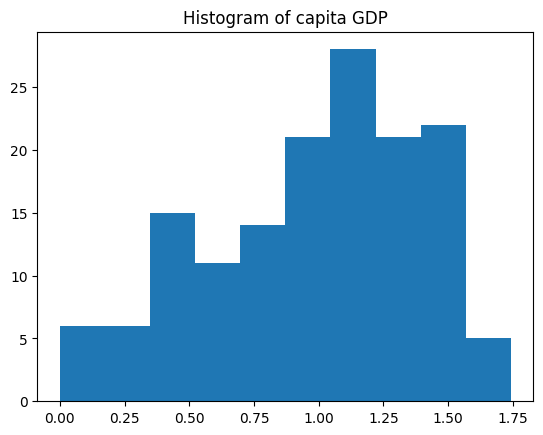

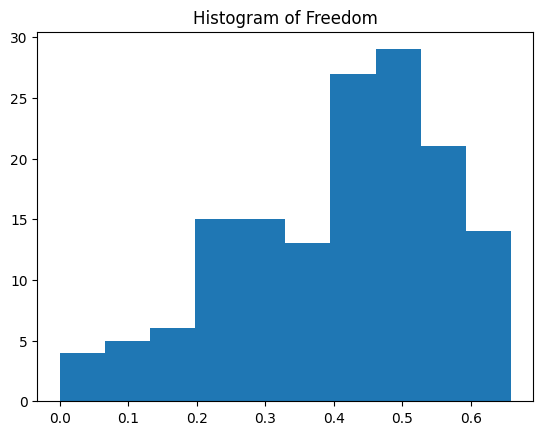

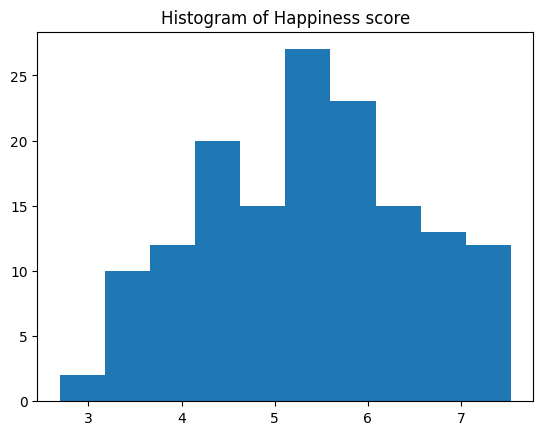

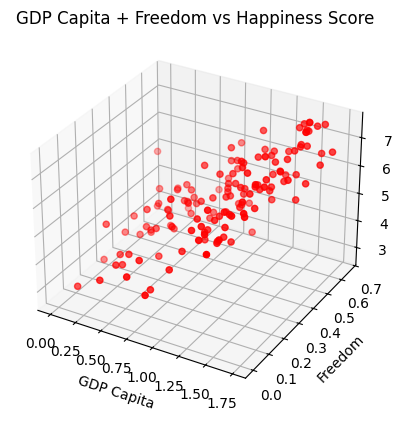


Pas 2



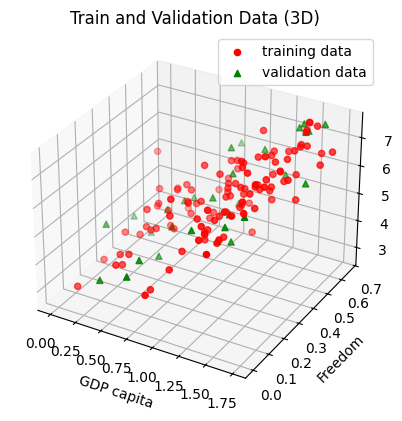


Pas 3

The learnt model: f(x1, x2) = 2.5467 + (1.9209) * x1 + (2.2406) * x2
The learnt model: f(x1, x2) = 2.5467 + (1.9209) * x1 + (2.2406) * x2

Pas 4



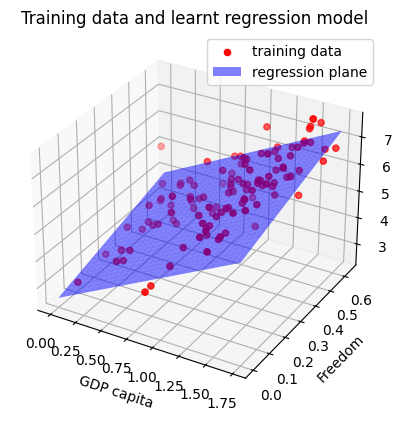

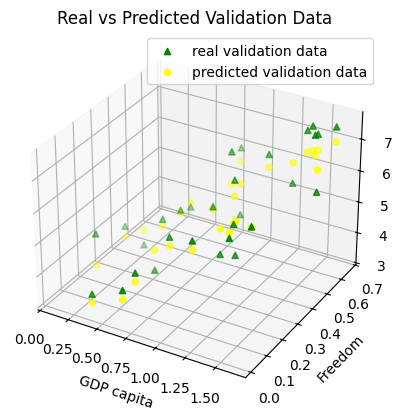


Pas 5

prediction error (manual):  0.3239053614564407
prediction error (tool):   0.32390536145644067


In [23]:
# DATE V3 -> GDP + Freedom


print("Pas 1")
print()

crtDir =  os.getcwd()
filePath = os.path.join(crtDir, 'data', 'v3_world-happiness-report-2017.csv')

firstInputs, secondInputs, outputs = loadData(filePath, 'Economy..GDP.per.Capita.', 'Freedom', 'Happiness.Score')
print('in:  ', firstInputs[:5])
print('in:  ', secondInputs[:5])
print('out: ', outputs[:5])



plotDataHistogram(firstInputs, 'capita GDP')
plotDataHistogram(secondInputs, 'Freedom')
plotDataHistogram(outputs, 'Happiness score')


checkLinearity3D(firstInputs, secondInputs, outputs)

print()
print("Pas 2")
print()


inputs = [list(x) for x in zip(firstInputs, secondInputs)]
trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)
plotTrainParams3D(trainInputs, trainOutputs, validationInputs, validationOutputs)


print()
print("Pas 3")
print()


trainInputs, trainOutputs, validationInputs, validationOutputs = splitTrainingTest2D(inputs, outputs)

regressor, w0, w = trainWithTool2D(trainInputs, trainOutputs)
printToolRegression2D(w0, w)

regressor, w0, w = trainWithDevelopedCode2D(trainInputs, trainOutputs)
printDevelopedRegression2D(w0, w)


print()
print("Pas 4")
print()


plotLearntModel2D(trainInputs, trainOutputs)
computedValidationOutputs = predictData2D(trainInputs, trainOutputs, validationInputs)
plotComputedValidationOutputs3D(validationInputs, validationOutputs, computedValidationOutputs)


print()
print("Pas 5")
print()


computedValidationOutputs = predictData2D(trainInputs, trainOutputs, validationInputs)
getError(computedValidationOutputs, validationOutputs)
